# Standalone Regularized Logistic Regression — IT24100879

Supplementary demonstration by IT24100879 alongside the group models. This
is a tuned model on the approved numeric and categorical predictors, **without
PCA**. The shared PCA benchmark answers a different representation question.

We demonstrate regularization, fold-local preprocessing, probability evaluation,
interpretable coefficients and an academic risk × retention-value-proxy score.
Logistic Regression is a plausible probability baseline; calibration and useful
risk ranking must be supported by evidence rather than assumed.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'configs/feature_contract.yaml').is_file())
sys.path.insert(0, str(ROOT))
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
from src.models.logistic_regression_experiment import run, DIRECTORY, MODEL_NAME
from src.evaluation.inputs import load_saved_model_evidence
OUT = ROOT / DIRECTORY
RUN_EXPERIMENT = False  # Explicitly enable for 55 model fits; saved review is the default.
if RUN_EXPERIMENT:
    run(ROOT)


## Data and leakage boundaries

The loader checks the frozen source and registry hashes and isolates development
rows before parsing predictors and targets. The five saved outer folds each hold
out 16,000 of the 80,000 development records. The formal 20,000-row holdout is not
used. Identifiers are output keys and ranking tie breakers, never predictors.

Shapes and target counts are logged during training. No rows are dropped or
resampled. The roughly 10% positive class motivates stratified inner splitting,
AP comparisons against prevalence, and explicit weighting experiments. Accuracy
alone is insufficient. Saved review verifies OOF IDs, folds, labels and metrics.


In [2]:
oof, folds, summary = load_saved_model_evidence(ROOT, MODEL_NAME, OUT)
display(pd.Series(summary, name='value').to_frame())
display(folds)


Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,value
average_precision,0.099964
roc_auc,0.498385
precision,0.0
recall,0.0
f1,0.0
balanced_accuracy,0.5
accuracy,0.8999
brier_score,0.090101
tn,71992
fp,0


,fold,candidate_id,C,class_weight,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,log_loss,baseline_log_loss,baseline_brier
0,1,L01,0.001,none,0.099523,0.495580,0.0,0.0,0.0,0.5,0.899937,0.090080,14399,0,1601,0,0,0.0,0.325389,0.325220,0.09005
1,2,L01,0.001,none,0.102165,0.503717,0.0,0.0,0.0,0.5,0.899937,0.090059,14399,0,1601,0,0,0.0,0.325272,0.325220,0.09005
2,3,L01,0.001,none,0.100688,0.498805,0.0,0.0,0.0,0.5,0.899875,0.090111,14398,0,1602,0,0,0.0,0.325420,0.325358,0.09010
3,4,L01,0.001,none,0.099411,0.493964,0.0,0.0,0.0,0.5,0.899875,0.090142,14398,0,1602,0,0,0.0,0.325593,0.325358,0.09010
4,5,L01,0.001,none,0.099719,0.499415,0.0,0.0,0.0,0.5,0.899875,0.090113,14398,0,1602,0,0,0.0,0.325425,0.325358,0.09010


## Regularization and tuning rationale

Numeric predictors are standardized because L2 shrinkage depends on feature scale.
Categorical predictors use training-fitted one-hot encoding with a dropped reference
level; unknown categories are handled without refitting. No PCA is fitted.

For each outer training partition, a stratified 15% inner validation split compares
five C values (0.001, 0.01, 0.1, 1, 10), each with unweighted and balanced weighting.
Smaller C means stronger L2 shrinkage. **Minimum inner log loss** chooses the
candidate, then preprocessing and the model are refitted on all outer training
rows. Outer validation is scored only after selection. There are 50 inner fits
and 5 selected refits. A single inner split is a bounded tuning demonstration;
repeated inner CV could improve selection stability.

Log loss is a proper probability scoring rule, aligned with probability × proxy
use. AP and ROC-AUC remain reported for discrimination. Balanced weights may
improve minority detection while shifting probabilities away from prevalence;
we allow validation evidence to choose rather than applying weights by default.


In [3]:
candidates = pd.read_csv(OUT / 'inner_candidate_metrics.csv')
display(candidates.groupby(['candidate_id', 'C', 'class_weight'], dropna=False)[
    ['inner_log_loss', 'inner_average_precision', 'inner_brier_score']].mean().reset_index())
evidence = json.loads((OUT / 'selection_evidence.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k: v for k, v in item.items() if k != 'candidates'} for item in evidence]))


,candidate_id,C,class_weight,inner_log_loss,inner_average_precision,inner_brier_score
0,L01,0.001,NaN,0.325454,0.098470,0.090110
1,L02,0.001,balanced,0.692956,0.098425,0.249904
2,L03,0.010,NaN,0.325625,0.098328,0.090141
3,L04,0.010,balanced,0.692996,0.098204,0.249925
4,L05,0.100,NaN,0.325701,0.098398,0.090155
5,L06,0.100,balanced,0.693053,0.098111,0.249954
6,L07,1.000,NaN,0.325709,0.098460,0.090156
7,L08,1.000,balanced,0.693076,0.098103,0.249965
8,L09,10.000,NaN,0.325710,0.098463,0.090156
9,L10,10.000,balanced,0.693077,0.098106,0.249966


,outer_fold,inner_train_rows,inner_validation_rows,outer_train_rows,outer_validation_rows,winner,selection_metric
0,1,54400,9600,64000,16000,L01,minimum inner log loss
1,2,54400,9600,64000,16000,L01,minimum inner log loss
2,3,54400,9600,64000,16000,L01,minimum inner log loss
3,4,54400,9600,64000,16000,L01,minimum inner log loss
4,5,54400,9600,64000,16000,L01,minimum inner log loss


## Calibration and discrimination

Compare log loss and Brier score against predictions equal to each outer training
fold's prevalence. AP's no-skill reference is positive prevalence; ROC-AUC's is
0.5. Reliability bins compare mean risk with observed resignation frequency.
Quantile bins help when probabilities cluster tightly. Ten-bin reliability is
descriptive, without confidence intervals; good calibration can coexist with
near-random discrimination. Probabilities have not been recalibrated using outer
labels. Threshold 0.5 is fixed, not optimized; low recall is possible at 10% prevalence.


,metric,model,reference
0,Log loss (lower better),0.325420,0.325303
1,Brier (lower better),0.090101,0.090080
2,AP (higher better),0.099964,0.100100


,mean_predicted_probability,observed_resignation_rate
0,0.093283,0.106125
1,0.095835,0.097250
2,0.097262,0.102375
3,0.098410,0.094875
4,0.099485,0.104250
5,0.100542,0.097500
6,0.101652,0.098125
7,0.102860,0.096375
8,0.104372,0.103875
9,0.107259,0.100250


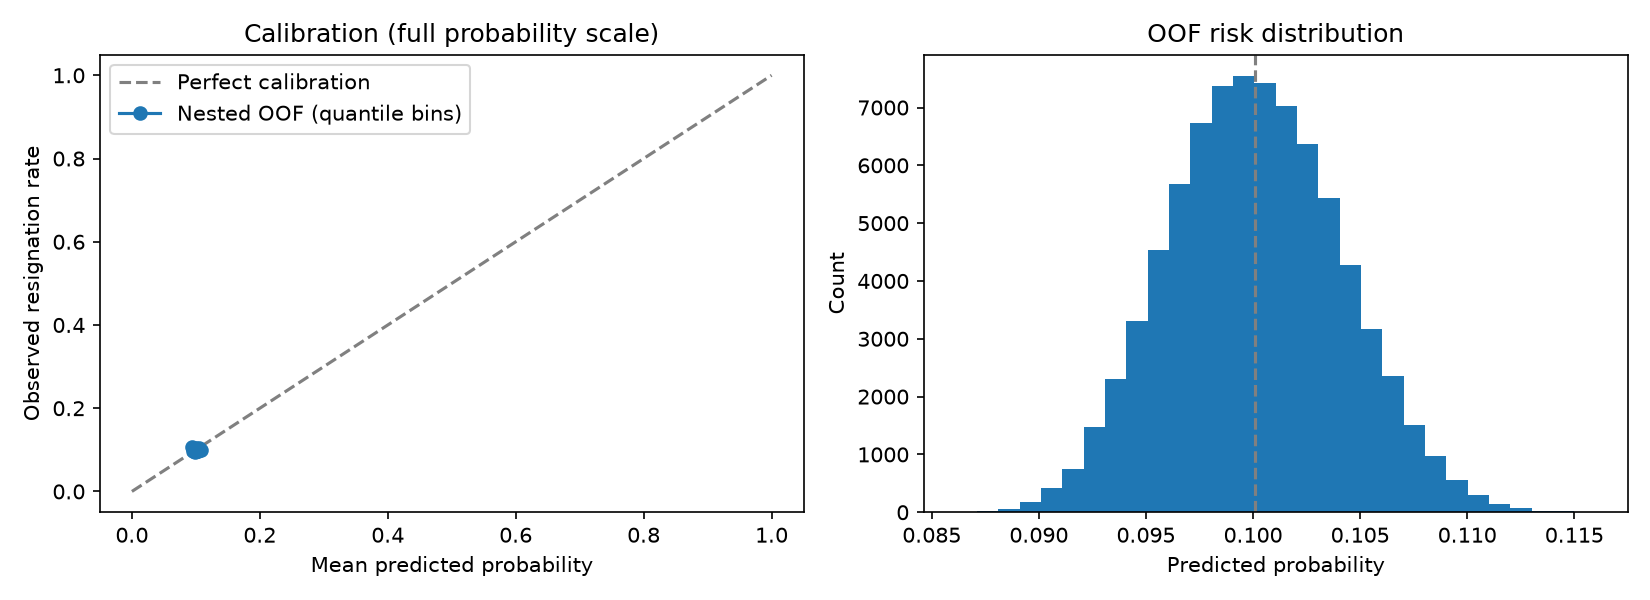

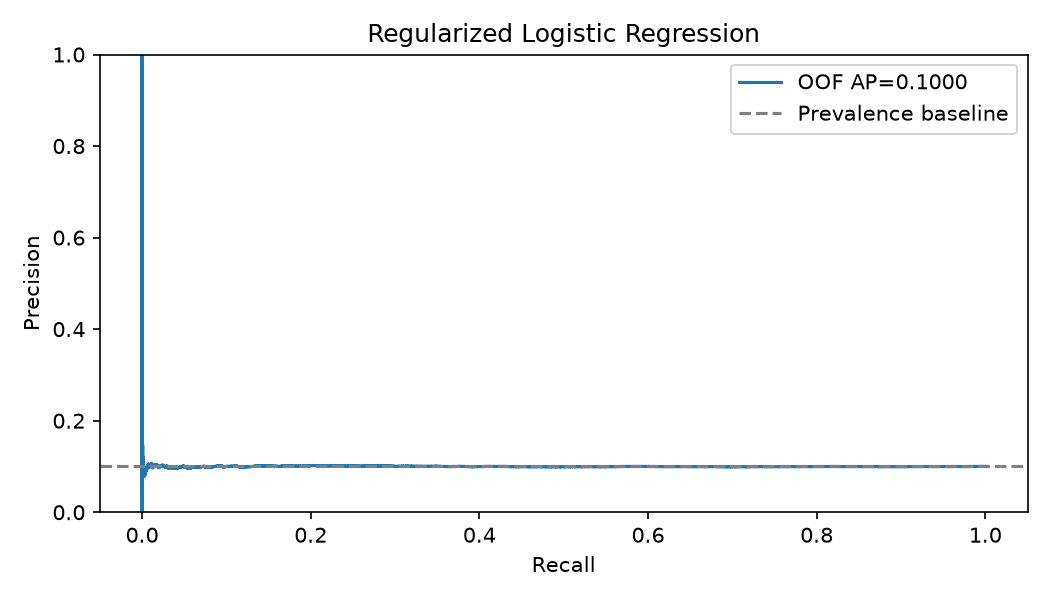

In [4]:
display(pd.DataFrame({
    'metric': ['Log loss (lower better)', 'Brier (lower better)', 'AP (higher better)'],
    'model': [summary['log_loss'], summary['brier_score'], summary['average_precision']],
    'reference': [summary['mean_baseline_log_loss'], summary['mean_baseline_brier'], summary['prevalence']]
}))
display(pd.read_csv(OUT / 'calibration_bins.csv'))
display(Image(filename=str(OUT / 'calibration.png')))
display(Image(filename=str(OUT / 'precision_recall_curve.png')))


## Explain the prediction

The model computes `z = intercept + sum(coefficient * transformed_feature)`, then
`p = 1 / (1 + exp(-z))`. Positive coefficients increase log odds, conditional on
other predictors; negative coefficients decrease them. Numeric coefficients refer
to one training-standard-deviation change. Categorical coefficients compare to
the encoder's reference category. L2 shrinks coefficients without forcing sparsity.
The following illustration belongs to fold 1's selected model, not an all-data
deployment model. Correlated predictors can affect coefficients; associations
do not establish causal resignation drivers.


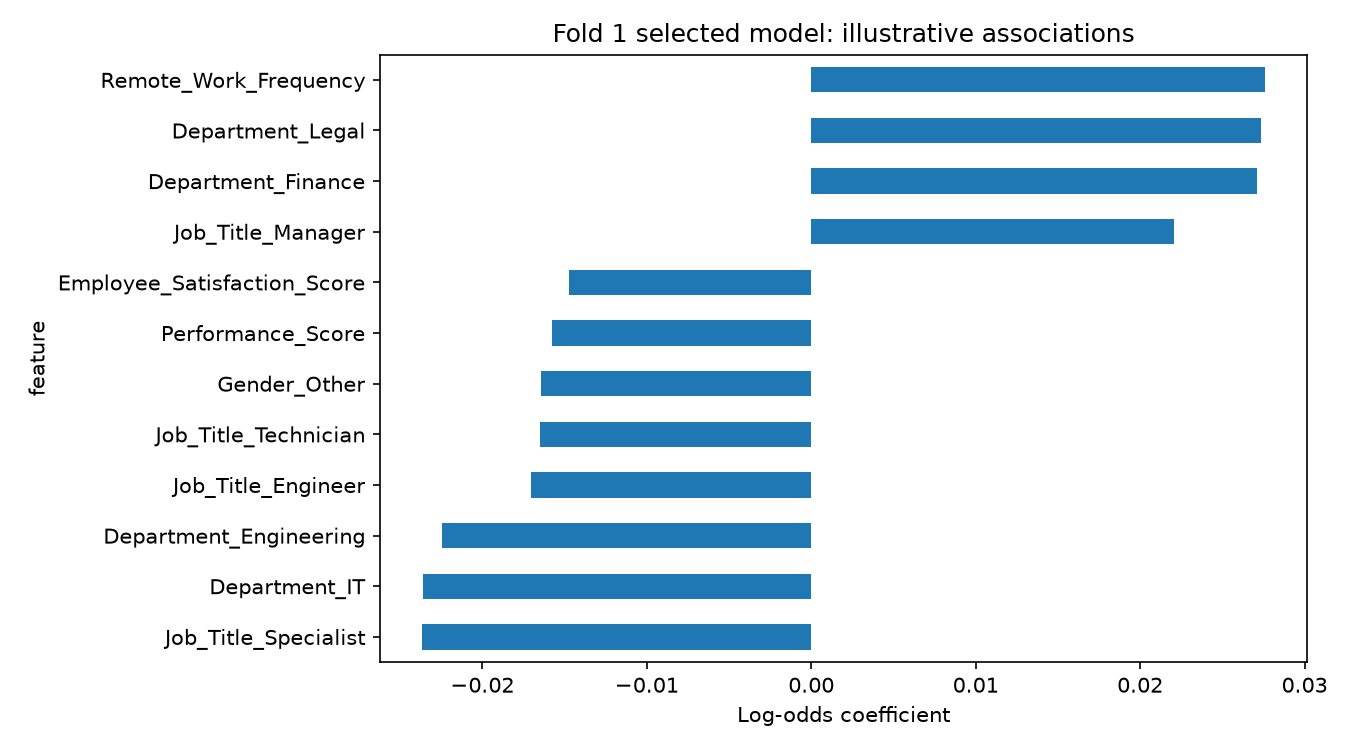

In [5]:
display(Image(filename=str(OUT / 'coefficients.png')))


## Risk × retention-value-proxy demonstration

The proxy equals the mean of normalized Performance_Score, Monthly_Salary and
Years_At_Company. Min/max values are fitted on each outer training set and held
fixed for its validation records; values outside the range are clipped. This
preserves the group proxy's components while avoiding validation-fitted bounds.

`combined_score = out_of_fold_probability * retention_value_proxy`

For example, synthetic risk 0.12 and proxy 0.75 produce score 0.09. The product
is a ranking score, not a resignation probability or expected intervention gain.
It does not measure employee worth. Risk-only, proxy-only and combined selection
are evaluated independently within each validation fold at 10%, 20%, 30% capacity.
The figure averages fold lift, with descriptive fold SD. Random expected lift is
1; no empirical random-allocation uncertainty is claimed.


,example,risk_probability,retention_value_proxy,combined_score
0,A,0.12,0.75,0.090
2,C,0.08,0.90,0.072
1,B,0.18,0.40,0.072


,capacity,strategy,selected_count,captured_positive_count,precision_at_capacity,recall_at_capacity,lift_at_capacity,captured_positive_proxy_value,value_weighted_recall_at_capacity,selected_proxy_value_share
0,0.1,combined_score,1600.0,155.0,0.096875,0.096778,0.967782,128.509709,0.167424,0.172818
1,0.1,retention_value_proxy,1600.0,157.4,0.098375,0.098277,0.982766,131.041553,0.170748,0.173637
2,0.1,y_probability,1600.0,159.6,0.099750,0.099651,0.996509,65.145307,0.084976,0.086313
3,0.2,combined_score,3200.0,320.4,0.100125,0.200049,1.000246,245.784693,0.320188,0.319900
4,0.2,retention_value_proxy,3200.0,320.4,0.100125,0.200050,1.000248,246.477799,0.321114,0.320826
5,0.2,y_probability,3200.0,321.2,0.100375,0.200549,1.002747,136.922524,0.178532,0.178001
6,0.3,combined_score,4800.0,481.0,0.100208,0.300324,1.001079,347.205275,0.452361,0.451205
7,0.3,retention_value_proxy,4800.0,480.4,0.100083,0.299948,0.999827,347.559223,0.452820,0.452138
8,0.3,y_probability,4800.0,483.0,0.100625,0.301573,1.005243,211.085793,0.275194,0.273338


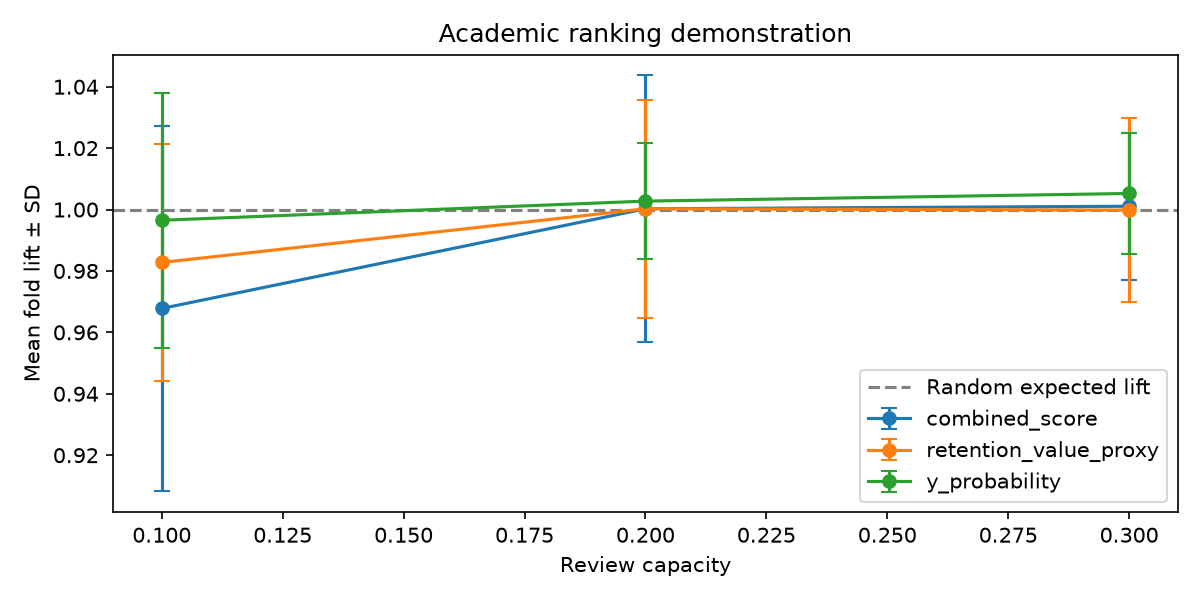

In [6]:
synthetic_demo = pd.DataFrame({'example': ['A', 'B', 'C'],
    'risk_probability': [0.12, 0.18, 0.08], 'retention_value_proxy': [0.75, 0.40, 0.90]})
synthetic_demo['combined_score'] = synthetic_demo.risk_probability * synthetic_demo.retention_value_proxy
display(synthetic_demo.sort_values('combined_score', ascending=False))
display(pd.read_csv(OUT / 'ranking_summary.csv'))
display(Image(filename=str(OUT / 'ranking.png')))


## Evidence-based conclusion and demo sequence

1. Explain smaller C and the leakage-safe training pipeline.
2. Show inner selection, then outer OOF metrics against prevalence baselines.
3. Inspect calibration and risk spread separately from AP and ROC-AUC.
4. Explain one fold's coefficients and the synthetic risk × proxy example.
5. Compare capacity lift and explain the evidence limits.

The next cell states the observed outcome against the prevalence references.
Small differences are descriptive, not proof of practical improvement. This
supplementary demonstration neither changes the six headline models nor freezes
a deployment model. The OOF file stays local and is ignored by Git; this notebook
shows aggregate evidence and synthetic examples rather than employee records.

**Observed outcome:** All five folds selected C=0.001 with no class weighting.
OOF AP=0.099964 versus prevalence 0.100100; ROC-AUC=0.498385.
Log loss and Brier are slightly worse than the prevalence baseline.
The combined score has mean fold lift 1.00025 at 20% capacity.
These results show essentially chance ranking despite probabilities clustered
near the observed resignation rate. At threshold 0.50, no positives are predicted.
This is a useful demonstration of method and limitations, with no evidence of
useful resignation discrimination or improved retention decisions.


In [7]:
print(f"OOF AP: {summary['average_precision']:.6f}; prevalence reference: {summary['prevalence']:.6f}")
print(f"OOF ROC-AUC: {summary['roc_auc']:.6f}; chance reference: 0.500000")
print(f"Log loss: {summary['log_loss']:.6f}; training-prevalence baseline: {summary['mean_baseline_log_loss']:.6f}")
print(f"Brier: {summary['brier_score']:.6f}; training-prevalence baseline: {summary['mean_baseline_brier']:.6f}")
print('Calibration does not establish useful risk ranking or retention intervention benefit.')
assert summary['formal_holdout_accessed'] is False
assert summary['inner_fits'] == 50 and summary['outer_refits'] == 5
print('Saved review completed; formal holdout excluded.')


OOF AP: 0.099964; prevalence reference: 0.100100
OOF ROC-AUC: 0.498385; chance reference: 0.500000
Log loss: 0.325420; training-prevalence baseline: 0.325303
Brier: 0.090101; training-prevalence baseline: 0.090080
Calibration does not establish useful risk ranking or retention intervention benefit.
Saved review completed; formal holdout excluded.
